# Machine Learning Pipeline: 30-Day Customer Churn Risk


In [1]:
#experimental configuration for version 2
SNAPSHOT_FREQUENCY = "7D"
PREDICTION_HORIZON_DAYS = 30
TARGET_COLUMN = "churn_next_30d"

## 1. Environment and database connection


In [3]:
from pathlib import Path

import importlib
import sys

import pandas as pd


PROJECT_ROOT = Path(
    "C:/Users/kipch/PycharmProjects/Customer_retention"
)

SRC_PATH = PROJECT_ROOT / "my_src"

if str(SRC_PATH) not in sys.path:
    sys.path.append(
        str(SRC_PATH)
    )

print(
    f"Project root: {PROJECT_ROOT}"
)

print(
    f"Source path: {SRC_PATH}"
)

Project root: C:\Users\kipch\PycharmProjects\Customer_retention
Source path: C:\Users\kipch\PycharmProjects\Customer_retention\my_src


In [142]:
import db_connector

importlib.reload(
    db_connector
)

from db_connector import DatabaseConnector

In [143]:
connector = DatabaseConnector(database='ravenstack_dw')

if hasattr(
    connector,
    "get_engine"
):
    engine = connector.get_engine()

elif hasattr(
    connector,
    "create_engine"
):
    engine = connector.create_engine()

elif hasattr(
    connector,
    "connect"
):
    engine = connector.connect()

elif hasattr(
    connector,
    "engine"
):
    engine = connector.engine

else:
    raise AttributeError(
        "DatabaseConnector does not expose an engine."
    )

In [5]:
#checking the length of the tables loaded.
table_check = pd.read_sql(
    """
    SELECT
        table_name,
        table_rows
    FROM information_schema.tables
    WHERE table_schema = DATABASE()
    ORDER BY table_name;
    """,
    engine
)

table_check

,TABLE_NAME,TABLE_ROWS
0,raw_accounts,500
1,raw_churn_events,600
2,raw_feature_usage,24186
3,raw_subscriptions,4984
4,raw_support_tickets,2000


## 2. Build weekly customer snapshots


In [6]:
import feature_engineering.snapshot_builder

importlib.reload(
    feature_engineering.snapshot_builder
)

from feature_engineering.snapshot_builder import (
    SnapshotBuilder
)


In [7]:
snapshot_builder = SnapshotBuilder(
    engine=engine,
    observation_end_date="2024-12-31",
    prediction_horizon_days=PREDICTION_HORIZON_DAYS
)

snapshots = snapshot_builder.build_snapshots(
    start_date="2023-01-15",
    frequency=SNAPSHOT_FREQUENCY
)

snapshots.head()

,account_id,snapshot_date
0,A-779e4e,2023-01-15
1,A-af0cd2,2023-01-15
2,A-779e4e,2023-01-22
3,A-af0cd2,2023-01-22
4,A-779e4e,2023-01-29


In [8]:
snapshot_check = {
    "rows": len(snapshots),

    "customers": (
        snapshots[
            "account_id"
        ].nunique()
    ),

    "snapshot_weeks": (
        snapshots[
            "snapshot_date"
        ].nunique()
    ),

    "first_snapshot": (
        snapshots[
            "snapshot_date"
        ].min()
    ),

    "last_snapshot": (
        snapshots[
            "snapshot_date"
        ].max()
    ),

    "duplicates": int(
        snapshots.duplicated(
            subset=[
                "account_id",
                "snapshot_date"
            ]
        ).sum()
    )
}

snapshot_check#


{'rows': 19955,
 'customers': 476,
 'snapshot_weeks': 99,
 'first_snapshot': Timestamp('2023-01-15 00:00:00'),
 'last_snapshot': Timestamp('2024-12-01 00:00:00'),
 'duplicates': 0}

## 3. Construct the 30-day target


In [9]:
import feature_engineering.target_builder

importlib.reload(
    feature_engineering.target_builder
)

from feature_engineering.target_builder import (
    TargetBuilder
)

In [10]:
target_builder = TargetBuilder(
    engine=engine
)

modeling_base = (
    target_builder.add_churn_target(
        snapshots_df=snapshots,
        prediction_window_days=PREDICTION_HORIZON_DAYS
    )
)

modeling_base.head()

,account_id,snapshot_date,churn_next_30d
0,A-779e4e,2023-01-15,0
1,A-af0cd2,2023-01-15,0
2,A-779e4e,2023-01-22,0
3,A-af0cd2,2023-01-22,0
4,A-779e4e,2023-01-29,0


In [11]:
target_check = {
    "rows": len(modeling_base),

    "customers": (
        modeling_base[
            "account_id"
        ].nunique()
    ),

    "snapshot_weeks": (
        modeling_base[
            "snapshot_date"
        ].nunique()
    ),

    "first_snapshot": (
        modeling_base[
            "snapshot_date"
        ].min()
    ),

    "last_snapshot": (
        modeling_base[
            "snapshot_date"
        ].max()
    ),

    "positive_targets": int(
        modeling_base[
            TARGET_COLUMN
        ].sum()
    ),

    "negative_targets": int(
        (
            modeling_base[
                TARGET_COLUMN
            ] == 0
        ).sum()
    ),

    "positive_rate": float(
        modeling_base[
            TARGET_COLUMN
        ].mean()
    ),

    "target_values": sorted(
        modeling_base[
            TARGET_COLUMN
        ].unique()
    ),

    "duplicates": int(
        modeling_base.duplicated(
            subset=[
                "account_id",
                "snapshot_date"
            ]
        ).sum()
    )
}

target_check

{'rows': 19955,
 'customers': 476,
 'snapshot_weeks': 99,
 'first_snapshot': Timestamp('2023-01-15 00:00:00'),
 'last_snapshot': Timestamp('2024-12-01 00:00:00'),
 'positive_targets': 1757,
 'negative_targets': 18198,
 'positive_rate': 0.08804810824354799,
 'target_values': [np.int64(0), np.int64(1)],
 'duplicates': 0}

## 4. Engineer point-in-time features


In [12]:
import feature_engineering.feature_engineer

importlib.reload(
    feature_engineering.feature_engineer
)

from feature_engineering.feature_engineer import (
    FeatureEngineer
)

In [13]:
feature_engineer = FeatureEngineer(
    engine=engine
)

modeling_df_v2 = feature_engineer.build_all_features(
    snapshots_df=modeling_base,
    target_column=TARGET_COLUMN
)

print(
    "Feature engineering completed."
)

print(
    f"Shape: {modeling_df_v2.shape}"
)

Feature engineering completed.
Shape: (19955, 35)


In [14]:
modeling_df_v2.head(5)

,account_id,snapshot_date,churn_next_30d,industry,country,referral_source,signup_date,tenure_days,current_plan_tier,current_seats,...,usage_log_change_30d,error_rate_30d,usage_per_seat_30d,ticket_count_30d,open_ticket_count,high_priority_ticket_count_30d,avg_satisfaction_90d,has_satisfaction_90d,days_since_last_ticket,ticket_log_change_30d
0,A-779e4e,2023-01-15,0,HealthTech,US,organic,2023-01-02,13,Basic,9,...,3.258097,0.040000,2.777778,0,0,0,NaN,0,NaN,0.000000
1,A-af0cd2,2023-01-15,0,Cybersecurity,IN,other,2023-01-03,12,Pro,19,...,2.772589,0.000000,0.789474,0,0,0,NaN,0,NaN,0.000000
2,A-779e4e,2023-01-22,0,HealthTech,US,organic,2023-01-02,20,Basic,9,...,3.258097,0.040000,2.777778,0,0,0,NaN,0,NaN,0.000000
3,A-af0cd2,2023-01-22,0,Cybersecurity,IN,other,2023-01-03,19,Pro,19,...,2.772589,0.000000,0.789474,0,0,0,NaN,0,NaN,0.000000
4,A-779e4e,2023-01-29,0,HealthTech,US,organic,2023-01-02,27,Enterprise,18,...,3.912023,0.020408,2.722222,1,0,1,3.0,1,2.0,0.693147


### Validate the modelling foundation


In [15]:
forbidden_columns = [
    "churn_date",
    "future_churn",
    "days_until_churn",
    "next_churn_date",
    "churn_in_prediction_window"
]

found_forbidden_columns = [
    column
    for column in forbidden_columns
    if column in modeling_df_v2.columns
]

print(
    "Forbidden leakage columns found:",
    found_forbidden_columns
)

Forbidden leakage columns found: []


In [16]:
len(modeling_df_v2)

19955

In [17]:
foundation_check = {
    "rows": len(modeling_df_v2),

    "columns": (
        modeling_df_v2.shape[1]
    ),

    "customers": (
        modeling_df_v2[
            "account_id"
        ].nunique()
    ),

    "snapshot_weeks": (
        modeling_df_v2[
            "snapshot_date"
        ].nunique()
    ),

    "first_snapshot": (
        modeling_df_v2[
            "snapshot_date"
        ].min()
    ),

    "last_snapshot": (
        modeling_df_v2[
            "snapshot_date"
        ].max()
    ),

    "positive_targets": int(
        modeling_df_v2[
            "churn_next_30d"
        ].sum()
    ),

    "duplicate_customer_weeks": int(
        modeling_df_v2.duplicated(
            subset=[
                "account_id",
                "snapshot_date"
            ]
        ).sum()
    )
}

foundation_check

{'rows': 19955,
 'columns': 35,
 'customers': 476,
 'snapshot_weeks': 99,
 'first_snapshot': Timestamp('2023-01-15 00:00:00'),
 'last_snapshot': Timestamp('2024-12-01 00:00:00'),
 'positive_targets': 1757,
 'duplicate_customer_weeks': 0}

In [18]:
feature_list = pd.DataFrame(
    {
        "feature": (
            modeling_df_v2.columns
        )
    }
)

feature_list

,feature
0,account_id
1,snapshot_date
2,churn_next_30d
3,industry
4,country
5,referral_source
6,signup_date
7,tenure_days
8,current_plan_tier
9,current_seats


In [19]:
missing_summary = (
    pd.DataFrame(
        {
            "missing_count": (
                modeling_df_v2
                .isna()
                .sum()
            ),

            "missing_percentage": (
                modeling_df_v2
                .isna()
                .mean()
                .mul(100)
            )
        }
    )
    .query(
        "missing_count > 0"
    )
    .sort_values(
        "missing_percentage",
        ascending=False
    )
)

missing_summary

,missing_count,missing_percentage
avg_satisfaction_90d,14922,74.778251
days_since_last_ticket,1866,9.351040


In [20]:
required_missing_check = (
    modeling_df_v2[
        [
            "account_id",
            "snapshot_date",
            "churn_next_30d"
        ]
    ]
    .isna()
    .sum()
)

required_missing_check

account_id        0
snapshot_date     0
churn_next_30d    0
dtype: int64

## 5. Preprocessing and temporal model data


In [21]:
TARGET_COLUMN = "churn_next_30d"
PREDICTION_HORIZON_DAYS = 30

## 6. Train baseline models


In [37]:
import importlib
import modeling.model_trainer

importlib.reload(
    modeling.model_trainer
)

from modeling.model_trainer import ModelTrainer

In [38]:
BASELINE_MODEL_DIR = (
    PROJECT_ROOT
    / "models"
    / "v2_30d"
    / "baseline"
)

In [39]:
model_params = {

    # LOGISTIC REGRESSION

    "logistic_regression": {

        "penalty": "l2",

        "C": 1.0,

        "solver": "liblinear",

        "class_weight": "balanced",

        "max_iter": 2000,

        "random_state": 42
    },


    # RANDOM FOREST

    "random_forest": {

        "n_estimators": 300,

        "max_depth": None,

        "min_samples_split": 2,

        "min_samples_leaf": 1,

        "class_weight": "balanced",

        "n_jobs": -1,

        "random_state": 42
    },


    # XGBOOST

    "xgboost": {

        "n_estimators": 300,

        "learning_rate": 0.05,

        "max_depth": 4,

        "subsample": 0.8,

        "colsample_bytree": 0.8,

        "eval_metric": "logloss",

        "random_state": 42
    },


    # CATBOOST

    "catboost": {

        "iterations": 300,

        "learning_rate": 0.05,

        "depth": 6,

        "loss_function": "Logloss",

        "verbose": 0,

        "random_seed": 42
    }
}

In [40]:
trainer = ModelTrainer(
    model_params=model_params,
    save_dir=BASELINE_MODEL_DIR
)

In [41]:
trained_models = trainer.train(
    X_train=X_train_processed,
    y_train=y_train
)

Training rows: 7,431
Churners: 441
Churn rate: 5.93%

Training logistic_regression...
Completed in 0.11 seconds.
Saved to: C:\Users\kipch\PycharmProjects\Customer_retention\models\v2_30d\baseline\logistic_regression.joblib

Training random_forest...
Completed in 1.39 seconds.
Saved to: C:\Users\kipch\PycharmProjects\Customer_retention\models\v2_30d\baseline\random_forest.joblib

Training xgboost...
Completed in 0.51 seconds.
Saved to: C:\Users\kipch\PycharmProjects\Customer_retention\models\v2_30d\baseline\xgboost.joblib

Training catboost...
Completed in 2.28 seconds.
Saved to: C:\Users\kipch\PycharmProjects\Customer_retention\models\v2_30d\baseline\catboost.joblib


In [42]:
trained_models

{'logistic_regression': LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42,
                    solver='liblinear'),
 'random_forest': RandomForestClassifier(class_weight='balanced', n_estimators=300, n_jobs=-1,
                        random_state=42),
 'xgboost': XGBClassifier(base_score=None, booster=None, callbacks=None,
               colsample_bylevel=None, colsample_bynode=None,
               colsample_bytree=0.8, device=None, early_stopping_rounds=None,
               enable_categorical=False, eval_metric='logloss',
               feature_types=None, feature_weights=None, gamma=None,
               grow_policy=None, importance_type=None,
               interaction_constraints=None, learning_rate=0.05, max_bin=None,
               max_cat_threshold=None, max_cat_to_onehot=None,
               max_delta_step=None, max_depth=4, max_leaves=None,
               min_child_weight=None, missing=nan, monotone_constraints=None,
               multi_strategy=None,

In [28]:
preprocessor.build_preprocessor(
    X_train
)

print("Numerical features:")
for column in preprocessor.numeric_columns:
    print(" -", column)

print(
    "\nTotal numerical:",
    len(preprocessor.numeric_columns)
)

print("\nCategorical features:")
for column in preprocessor.categorical_columns:
    print(" -", column)

print(
    "\nTotal categorical:",
    len(preprocessor.categorical_columns)
)

Numerical features:
 - tenure_days
 - current_seats
 - current_mrr
 - current_is_trial
 - current_auto_renew_flag
 - current_subscription_age_days
 - completed_subscription_count
 - subscription_churn_count_to_date
 - reactivation_count_to_date
 - usage_count_7d
 - usage_count_30d
 - usage_duration_secs_30d
 - unique_features_30d
 - active_usage_days_30d
 - days_since_last_usage
 - usage_log_change_7d
 - usage_log_change_30d
 - error_rate_30d
 - usage_per_seat_30d
 - ticket_count_30d
 - open_ticket_count
 - high_priority_ticket_count_30d
 - avg_satisfaction_90d
 - has_satisfaction_90d
 - days_since_last_ticket
 - ticket_log_change_30d

Total numerical: 26

Categorical features:
 - industry
 - country
 - referral_source
 - current_plan_tier
 - current_billing_frequency

Total categorical: 5


In [30]:
# FIT PREPROCESSOR ON TRAINING DATA ONLY

X_train_processed = (
    preprocessor.preprocessor.fit_transform(
        X_train
    )
)


# TRANSFORM VALIDATION AND TEST

X_validation_processed = (
    preprocessor.preprocessor.transform(
        X_validation
    )
)

X_test_processed = (
    preprocessor.preprocessor.transform(
        X_test
    )
)

In [33]:
print(
    "Train processed:",
    X_train_processed.shape
)

print(
    "Validation processed:",
    X_validation_processed.shape
)

print(
    "Test processed:",
    X_test_processed.shape
)

print(
    "\nMissing values in train:",
    np.isnan(X_train_processed).sum()
)

print(
    "Missing values in validation:",
    np.isnan(X_validation_processed).sum()
)

print(
    "Missing values in test:",
    np.isnan(X_test_processed).sum()
)


Train processed: (7431, 48)
Validation processed: (3552, 48)
Test processed: (6383, 48)

Missing values in train: 0
Missing values in validation: 0
Missing values in test: 0


In [32]:
import numpy as np

In [34]:
import importlib
import modeling.model_trainer

importlib.reload(
    modeling.model_trainer
)

from modeling.model_trainer import ModelTrainer

In [35]:
model_params = {

    "logistic_regression": {
        "penalty": "l2",
        "C": 1.0,
        "solver": "liblinear",
        "class_weight": "balanced",
        "max_iter": 2000,
        "random_state": 42
    },

    "random_forest": {
        "n_estimators": 300,
        "max_depth": None,
        "min_samples_split": 2,
        "min_samples_leaf": 1,
        "class_weight": "balanced",
        "n_jobs": -1,
        "random_state": 42
    },

    "xgboost": {
        "n_estimators": 300,
        "learning_rate": 0.05,
        "max_depth": 4,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "eval_metric": "logloss",
        "random_state": 42
    },

    "catboost": {
        "iterations": 300,
        "learning_rate": 0.05,
        "depth": 6,
        "loss_function": "Logloss",
        "verbose": 0,
        "random_seed": 42
    }
}

In [43]:
trainer.training_summary

,model,training_seconds,model_path
0,logistic_regression,0.113768,C:\Users\kipch\PycharmProjects\Customer_retent...
1,random_forest,1.389101,C:\Users\kipch\PycharmProjects\Customer_retent...
2,xgboost,0.512419,C:\Users\kipch\PycharmProjects\Customer_retent...
3,catboost,2.280099,C:\Users\kipch\PycharmProjects\Customer_retent...


## 7. Evaluate baseline validation performance


In [44]:
import importlib
import modeling.model_evaluator

importlib.reload(
    modeling.model_evaluator
)

from modeling.model_evaluator import ModelEvaluator


In [45]:
BASELINE_RESULTS_DIR = (
    PROJECT_ROOT
    / "models"
    / "v2_30d"
    / "baseline"
    / "validation_results"
)

In [46]:
evaluator = ModelEvaluator(
    threshold=0.50,
    results_dir=BASELINE_RESULTS_DIR
)

In [47]:
validation_results = evaluator.evaluate(
    models=trained_models,
    X_validation=X_validation_processed,
    y_validation=y_validation
)

validation_results

Evaluating logistic_regression...
Evaluating random_forest...
Evaluating xgboost...
Evaluating catboost...

VALIDATION RESULTS SAVED

Models evaluated: 4
Prediction files saved: 4
Confusion matrices saved: 4

Results directory:
C:\Users\kipch\PycharmProjects\Customer_retention\models\v2_30d\baseline\validation_results

Metrics:
C:\Users\kipch\PycharmProjects\Customer_retention\models\v2_30d\baseline\validation_results\validation_metrics.csv


,model,threshold,rows,positive_rows,prevalence,pr_auc,pr_auc_lift,roc_auc,precision,recall,f1,true_positives,false_positives,false_negatives,true_negatives
0,xgboost,0.5,3552,341,0.096002,0.126400,1.316631,0.575917,0.100000,0.002933,0.005698,1,9,340,3202
1,random_forest,0.5,3552,341,0.096002,0.120501,1.255185,0.555598,0.000000,0.000000,0.000000,0,0,341,3211
2,logistic_regression,0.5,3552,341,0.096002,0.116799,1.216632,0.559072,0.104874,0.416422,0.167552,142,1212,199,1999
3,catboost,0.5,3552,341,0.096002,0.115833,1.206568,0.547629,0.000000,0.000000,0.000000,0,1,341,3210


In [48]:
validation_results[
    [
        "model",
        "pr_auc",
        "pr_auc_lift",
        "roc_auc",
        "precision",
        "recall",
        "f1",
        "true_positives",
        "false_positives",
        "false_negatives",
        "true_negatives"
    ]
]

,model,pr_auc,pr_auc_lift,roc_auc,precision,recall,f1,true_positives,false_positives,false_negatives,true_negatives
0,xgboost,0.126400,1.316631,0.575917,0.100000,0.002933,0.005698,1,9,340,3202
1,random_forest,0.120501,1.255185,0.555598,0.000000,0.000000,0.000000,0,0,341,3211
2,logistic_regression,0.116799,1.216632,0.559072,0.104874,0.416422,0.167552,142,1212,199,1999
3,catboost,0.115833,1.206568,0.547629,0.000000,0.000000,0.000000,0,1,341,3210


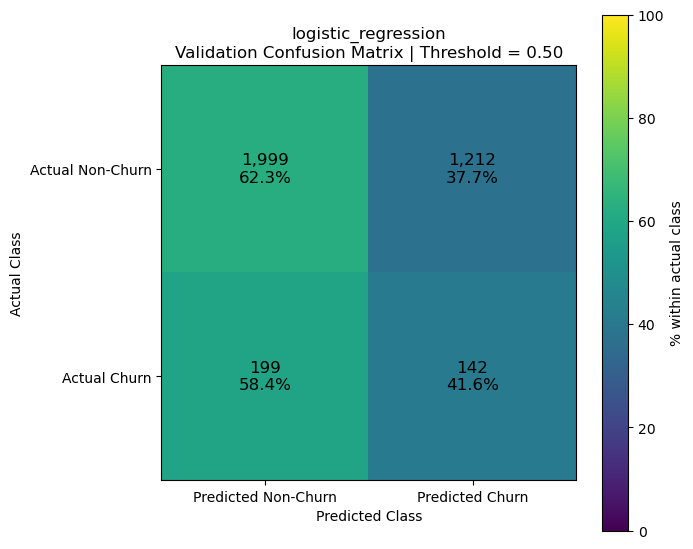

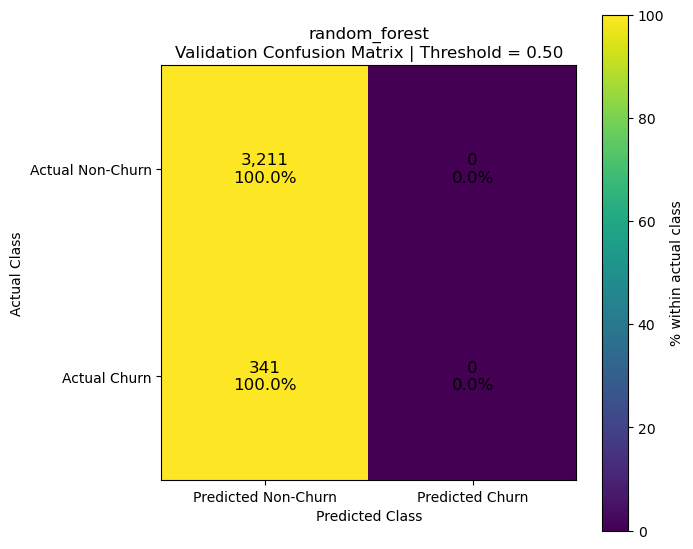

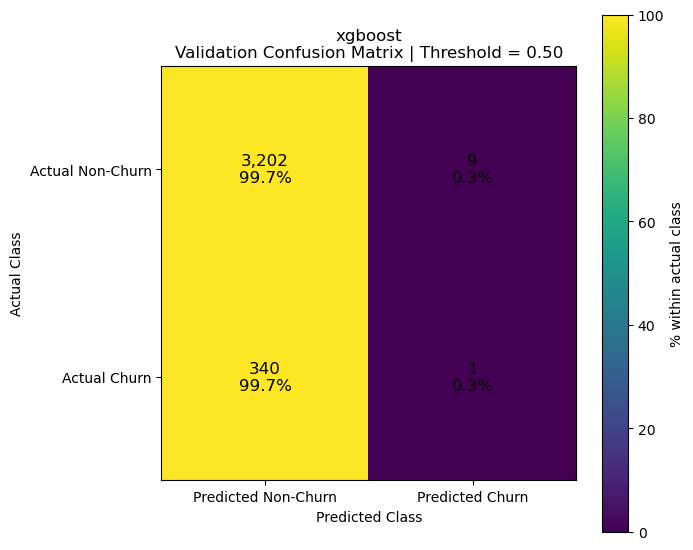

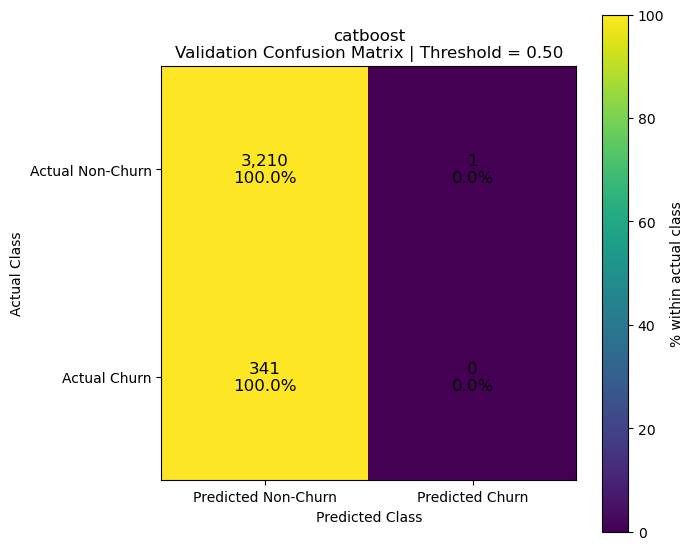

In [49]:
evaluator.show_all_confusion_matrices()

## 8. Hyperparameter tuning with temporal folds


In [50]:
import importlib
import modeling.model_tuner

importlib.reload(
    modeling.model_tuner
)

from modeling.model_tuner import ModelTuner

In [51]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier
from catboost import CatBoostClassifier


models_to_tune = {

    "logistic_regression":
        LogisticRegression(),

    "random_forest":
        RandomForestClassifier(),

    "xgboost":
        XGBClassifier(),

    "catboost":
        CatBoostClassifier(
            verbose=0
        )
}

In [52]:
logistic_grid = [

    # L2
    {
        "penalty": ["l2"],
        "solver": ["liblinear"],
        "C": [
            0.001,
            0.003,
            0.01,
            0.03,
            0.1,
            0.3,
            1.0,
            3.0,
            10.0,
            30.0,
            100.0
        ],
        "class_weight": [
            None,
            "balanced",
            {0: 1, 1: 2},
            {0: 1, 1: 3},
            {0: 1, 1: 5},
            {0: 1, 1: 8},
            {0: 1, 1: 12}
        ],
        "max_iter": [3000],
        "random_state": [42]
    },

    # L1
    {
        "penalty": ["l1"],
        "solver": ["liblinear"],
        "C": [
            0.001,
            0.003,
            0.01,
            0.03,
            0.1,
            0.3,
            1.0,
            3.0,
            10.0,
            30.0,
            100.0
        ],
        "class_weight": [
            None,
            "balanced",
            {0: 1, 1: 2},
            {0: 1, 1: 3},
            {0: 1, 1: 5},
            {0: 1, 1: 8},
            {0: 1, 1: 12}
        ],
        "max_iter": [3000],
        "random_state": [42]
    }
]


In [53]:
random_forest_grid = {

    "n_estimators": [
        300,
        600
    ],

    "max_depth": [
        None,
        5,
        10,
        15
    ],

    "min_samples_split": [
        2,
        10,
        25
    ],

    "min_samples_leaf": [
        1,
        5,
        10
    ],

    "max_features": [
        "sqrt",
        0.5
    ],

    "class_weight": [
        None,
        "balanced",
        "balanced_subsample"
    ],

    "bootstrap": [
        True
    ],

    "n_jobs": [
        -1
    ],

    "random_state": [
        42
    ]
}

In [54]:
xgboost_grid = {

    "n_estimators": [
        200,
        400,
        700
    ],

    "learning_rate": [
        0.01,
        0.03,
        0.07
    ],

    "max_depth": [
        2,
        3,
        5
    ],

    "min_child_weight": [
        1,
        5,
        10
    ],

    "subsample": [
        0.7,
        1.0
    ],

    "colsample_bytree": [
        0.7,
        1.0
    ],

    "reg_alpha": [
        0.0,
        0.5
    ],

    "reg_lambda": [
        1.0,
        5.0
    ],

    "scale_pos_weight": [
        1.0,
        5.0,
        10.0
    ],

    "eval_metric": [
        "logloss"
    ],

    "n_jobs": [
        -1
    ],

    "random_state": [
        42
    ]
}

In [55]:
catboost_grid = {

    "iterations": [
        300,
        600
    ],

    "learning_rate": [
        0.02,
        0.05,
        0.1
    ],

    "depth": [
        4,
        6,
        8
    ],

    "l2_leaf_reg": [
        1,
        5,
        10
    ],

    "random_strength": [
        0.5,
        1.0
    ],

    "class_weights": [
        None,
        [1, 3],
        [1, 5],
        [1, 10]
    ],

    "loss_function": [
        "Logloss"
    ],

    "verbose": [
        0
    ],

    "random_seed": [
        42
    ]
}

In [56]:
param_grids = {

    "logistic_regression":
        logistic_grid,

    "random_forest":
        random_forest_grid,

    "xgboost":
        xgboost_grid,

    "catboost":
        catboost_grid
}

In [57]:
from sklearn.model_selection import ParameterGrid


for model_name, grid in param_grids.items():

    combinations = len(
        list(
            ParameterGrid(grid)
        )
    )

    print(
        f"{model_name:25s} "
        f"{combinations:,} configurations | "
        f"{combinations * 5:,} fits"
    )

logistic_regression       154 configurations | 770 fits
random_forest             432 configurations | 2,160 fits
xgboost                   3,888 configurations | 19,440 fits
catboost                  432 configurations | 2,160 fits


In [58]:
train_snapshot_dates = (
    train_df["snapshot_date"]
    .reset_index(drop=True)
)

In [59]:
print(
    "X rows:",
    len(X_train_processed)
)

print(
    "y rows:",
    len(y_train)
)

print(
    "Date rows:",
    len(train_snapshot_dates)
)

X rows: 7431
y rows: 7431
Date rows: 7431


In [60]:
TUNING_DIR = (
    PROJECT_ROOT
    / "models"
    / "v2_30d"
    / "rigorous_tuning"
)


tuner = ModelTuner(

    models=models_to_tune,

    param_grids=param_grids,

    n_splits=5,

    gap_periods=4,

    save_dir=TUNING_DIR
)

In [61]:
folds = tuner.create_temporal_folds(
    snapshot_dates=train_snapshot_dates
)


for fold_number, (
    train_idx,
    validation_idx
) in enumerate(
    folds,
    start=1
):

    train_dates = (
        train_snapshot_dates
        .iloc[train_idx]
    )

    validation_dates = (
        train_snapshot_dates
        .iloc[validation_idx]
    )

    print(
        f"\nFold {fold_number}"
    )

    print(
        "Train:",
        train_dates.min(),
        "→",
        train_dates.max()
    )

    print(
        "Validation:",
        validation_dates.min(),
        "→",
        validation_dates.max()
    )

    print(
        "Date difference:",
        validation_dates.min()
        - train_dates.max()
    )


Fold 1
Train: 2023-01-15 00:00:00 → 2023-03-26 00:00:00
Validation: 2023-04-30 00:00:00 → 2023-07-02 00:00:00
Date difference: 35 days 00:00:00

Fold 2
Train: 2023-01-15 00:00:00 → 2023-06-04 00:00:00
Validation: 2023-07-09 00:00:00 → 2023-09-10 00:00:00
Date difference: 35 days 00:00:00

Fold 3
Train: 2023-01-15 00:00:00 → 2023-08-13 00:00:00
Validation: 2023-09-17 00:00:00 → 2023-11-19 00:00:00
Date difference: 35 days 00:00:00

Fold 4
Train: 2023-01-15 00:00:00 → 2023-10-22 00:00:00
Validation: 2023-11-26 00:00:00 → 2024-01-28 00:00:00
Date difference: 35 days 00:00:00

Fold 5
Train: 2023-01-15 00:00:00 → 2023-12-31 00:00:00
Validation: 2024-02-04 00:00:00 → 2024-04-07 00:00:00
Date difference: 35 days 00:00:00


In [62]:
tuning_results = tuner.tune(

    X_train=X_train_processed,

    y_train=y_train,

    snapshot_dates=train_snapshot_dates
)


TUNING: LOGISTIC_REGRESSION
Parameter combinations: 154
Temporal folds: 5
Total model fits: 770


Tuning logistic_regression:   0%|          | 0/154 [00:00<?, ?config/s]


Best logistic_regression CV PR-AUC: 0.05574

Best parameters:
  C: 0.003
  class_weight: None
  max_iter: 3000
  penalty: l1
  random_state: 42
  solver: liblinear

Retraining best logistic_regression on full training data...
Retraining completed in 0.01 seconds.

Best model saved to:
C:\Users\kipch\PycharmProjects\Customer_retention\models\v2_30d\rigorous_tuning\best_logistic_regression.joblib

Tuning results saved to:
C:\Users\kipch\PycharmProjects\Customer_retention\models\v2_30d\rigorous_tuning\logistic_regression_tuning_results.csv

Tuning metadata saved to:
C:\Users\kipch\PycharmProjects\Customer_retention\models\v2_30d\rigorous_tuning\logistic_regression_tuning_metadata.json

TUNING: RANDOM_FOREST
Parameter combinations: 432
Temporal folds: 5
Total model fits: 2,160


Tuning random_forest:   0%|          | 0/432 [00:00<?, ?config/s]


Best random_forest CV PR-AUC: 0.06643

Best parameters:
  bootstrap: True
  class_weight: None
  max_depth: 5
  max_features: 0.5
  min_samples_leaf: 1
  min_samples_split: 2
  n_estimators: 600
  n_jobs: -1
  random_state: 42

Retraining best random_forest on full training data...
Retraining completed in 9.87 seconds.

Best model saved to:
C:\Users\kipch\PycharmProjects\Customer_retention\models\v2_30d\rigorous_tuning\best_random_forest.joblib

Tuning results saved to:
C:\Users\kipch\PycharmProjects\Customer_retention\models\v2_30d\rigorous_tuning\random_forest_tuning_results.csv

Tuning metadata saved to:
C:\Users\kipch\PycharmProjects\Customer_retention\models\v2_30d\rigorous_tuning\random_forest_tuning_metadata.json

TUNING: XGBOOST
Parameter combinations: 3,888
Temporal folds: 5
Total model fits: 19,440


Tuning xgboost:   0%|          | 0/3888 [00:00<?, ?config/s]


Best xgboost CV PR-AUC: 0.06482

Best parameters:
  colsample_bytree: 0.7
  eval_metric: logloss
  learning_rate: 0.03
  max_depth: 3
  min_child_weight: 5
  n_estimators: 200
  n_jobs: -1
  random_state: 42
  reg_alpha: 0.5
  reg_lambda: 1.0
  scale_pos_weight: 1.0
  subsample: 1.0

Retraining best xgboost on full training data...
Retraining completed in 0.10 seconds.

Best model saved to:
C:\Users\kipch\PycharmProjects\Customer_retention\models\v2_30d\rigorous_tuning\best_xgboost.joblib

Tuning results saved to:
C:\Users\kipch\PycharmProjects\Customer_retention\models\v2_30d\rigorous_tuning\xgboost_tuning_results.csv

Tuning metadata saved to:
C:\Users\kipch\PycharmProjects\Customer_retention\models\v2_30d\rigorous_tuning\xgboost_tuning_metadata.json

TUNING: CATBOOST
Parameter combinations: 432
Temporal folds: 5
Total model fits: 2,160


Tuning catboost:   0%|          | 0/432 [00:00<?, ?config/s]

CatBoostError: catboost/private/libs/options/json_helper.h:41: Can't parse parameter "class_weights" with value: null

In [63]:
from catboost import CatBoostClassifier

from modeling.model_tuner import ModelTuner


# CATBOOST ONLY

catboost_models = {

    "catboost": CatBoostClassifier()

}


# RIGOROUS CATBOOST PARAMETER GRID

catboost_param_grids = {

    "catboost": [

        # UNWEIGHTED
        # class_weights deliberately NOT included

        {
            "iterations": [300, 600],

            "learning_rate": [
                0.02,
                0.05,
                0.1
            ],

            "depth": [
                4,
                6,
                8
            ],

            "l2_leaf_reg": [
                1,
                5,
                10
            ],

            "random_strength": [
                0.5,
                1.0
            ],

            "loss_function": [
                "Logloss"
            ],

            "verbose": [0],

            "random_seed": [42]
        },


        # WEIGHTED

        {
            "iterations": [300, 600],

            "learning_rate": [
                0.02,
                0.05,
                0.1
            ],

            "depth": [
                4,
                6,
                8
            ],

            "l2_leaf_reg": [
                1,
                5,
                10
            ],

            "random_strength": [
                0.5,
                1.0
            ],

            "class_weights": [
                [1, 3],
                [1, 5],
                [1, 10]
            ],

            "loss_function": [
                "Logloss"
            ],

            "verbose": [0],

            "random_seed": [42]
        }
    ]
}


# CREATE CATBOOST-ONLY TUNER

catboost_tuner = ModelTuner(

    models=catboost_models,

    param_grids=catboost_param_grids,

    n_splits=5,

    gap_periods=4,

    save_dir=(
        PROJECT_ROOT
        / "models"
        / "v2_30d"
        / "rigorous_tuning"
    )
)


# RUN CATBOOST TUNING

catboost_tuning_results = (
    catboost_tuner.tune(

        X_train=X_train_processed,

        y_train=y_train,

        snapshot_dates=train_snapshot_dates
    )
)


# DISPLAY RESULTS

catboost_tuning_results


TUNING: CATBOOST
Parameter combinations: 432
Temporal folds: 5
Total model fits: 2,160


Tuning catboost:   0%|          | 0/432 [00:00<?, ?config/s]


Best catboost CV PR-AUC: 0.07444

Best parameters:
  depth: 4
  iterations: 600
  l2_leaf_reg: 1
  learning_rate: 0.02
  loss_function: Logloss
  random_seed: 42
  random_strength: 0.5
  verbose: 0

Retraining best catboost on full training data...
Retraining completed in 2.15 seconds.

Best model saved to:
C:\Users\kipch\PycharmProjects\Customer_retention\models\v2_30d\rigorous_tuning\best_catboost.joblib

Tuning results saved to:
C:\Users\kipch\PycharmProjects\Customer_retention\models\v2_30d\rigorous_tuning\catboost_tuning_results.csv

Tuning metadata saved to:
C:\Users\kipch\PycharmProjects\Customer_retention\models\v2_30d\rigorous_tuning\catboost_tuning_metadata.json

Combined tuning results saved to:
C:\Users\kipch\PycharmProjects\Customer_retention\models\v2_30d\rigorous_tuning\all_tuning_results.csv


,model,parameters,mean_pr_auc,std_pr_auc,min_pr_auc,max_pr_auc,folds_used,training_seconds
0,catboost,"{'depth': 4, 'iterations': 600, 'l2_leaf_reg':...",0.074437,0.034219,0.040813,0.137738,5,3.870376
1,catboost,"{'depth': 4, 'iterations': 300, 'l2_leaf_reg':...",0.071937,0.030013,0.043164,0.128414,5,2.173289
2,catboost,"{'depth': 4, 'iterations': 600, 'l2_leaf_reg':...",0.071808,0.029181,0.043696,0.126889,5,3.846648
3,catboost,"{'depth': 4, 'iterations': 300, 'l2_leaf_reg':...",0.071061,0.023635,0.042018,0.110481,5,2.176588
4,catboost,"{'depth': 4, 'iterations': 300, 'l2_leaf_reg':...",0.070346,0.028033,0.040731,0.119450,5,3.821828
...,...,...,...,...,...,...,...,...
427,catboost,"{'class_weights': [1, 10], 'depth': 8, 'iterat...",0.049873,0.011943,0.032741,0.063727,5,16.605561
428,catboost,"{'class_weights': [1, 5], 'depth': 8, 'iterati...",0.049738,0.012073,0.032087,0.063872,5,16.984800
429,catboost,"{'class_weights': [1, 5], 'depth': 8, 'iterati...",0.049581,0.012235,0.031934,0.063796,5,8.638419
430,catboost,"{'class_weights': [1, 5], 'depth': 8, 'iterati...",0.049207,0.012292,0.034417,0.066655,5,8.723907


## 9. Compare tuned models on validation data


In [64]:
# LOAD RIGOROUSLY TUNED MODELS

from pathlib import Path
import joblib


TUNED_MODEL_DIR = (
    PROJECT_ROOT
    / "models"
    / "v2_30d"
    / "rigorous_tuning"
)


tuned_models = {

    "logistic_regression":
        joblib.load(
            TUNED_MODEL_DIR
            / "best_logistic_regression.joblib"
        ),

    "random_forest":
        joblib.load(
            TUNED_MODEL_DIR
            / "best_random_forest.joblib"
        ),

    "xgboost":
        joblib.load(
            TUNED_MODEL_DIR
            / "best_xgboost.joblib"
        ),

    "catboost":
        joblib.load(
            TUNED_MODEL_DIR
            / "best_catboost.joblib"
        )
}


print("Loaded tuned models:")

for model_name in tuned_models:
    print(f"  ✓ {model_name}")

Loaded tuned models:
  ✓ logistic_regression
  ✓ random_forest
  ✓ xgboost
  ✓ catboost


In [78]:
# TUNED VALIDATION RESULTS DIRECTORY

TUNED_VALIDATION_DIR = (
    PROJECT_ROOT
    / "models"
    / "v2_30d"
    / "tuned_validation"
)

TUNED_VALIDATION_DIR.mkdir(
    parents=True,
    exist_ok=True
)

In [79]:
# CREATE TUNED MODEL EVALUATOR

from modeling.model_evaluator import ModelEvaluator


tuned_evaluator = ModelEvaluator(

    threshold=0.50,

    results_dir=TUNED_VALIDATION_DIR
)

In [80]:
tuned_evaluator = ModelEvaluator(
    threshold=0.50,
     results_dir=TUNED_VALIDATION_DIR
)
tuned_validation_results = evaluator.evaluate(
    models=tuned_models,
    X_validation=X_validation_processed,
    y_validation=y_validation
)


Evaluating logistic_regression...
Evaluating random_forest...
Evaluating xgboost...
Evaluating catboost...

VALIDATION RESULTS SAVED

Models evaluated: 4
Prediction files saved: 4
Confusion matrices saved: 4

Results directory:
C:\Users\kipch\PycharmProjects\Customer_retention\models\v2_30d\baseline\validation_results

Metrics:
C:\Users\kipch\PycharmProjects\Customer_retention\models\v2_30d\baseline\validation_results\validation_metrics.csv


In [81]:
# DISPLAY TUNED VALIDATION RESULTS

tuned_validation_results

,model,threshold,rows,positive_rows,prevalence,pr_auc,pr_auc_lift,roc_auc,precision,recall,f1,true_positives,false_positives,false_negatives,true_negatives
0,xgboost,0.5,3552,341,0.096002,0.129853,1.352605,0.584746,0.0,0.0,0.0,0,0,341,3211
1,random_forest,0.5,3552,341,0.096002,0.119224,1.241886,0.581014,0.0,0.0,0.0,0,0,341,3211
2,catboost,0.5,3552,341,0.096002,0.117884,1.227934,0.580956,0.0,0.0,0.0,0,1,341,3210
3,logistic_regression,0.5,3552,341,0.096002,0.096002,1.000000,0.500000,0.0,0.0,0.0,0,0,341,3211


In [83]:
# EVALUATE TUNED MODELS ON OUTER VALIDATION SET

tuned_validation_results = (
    tuned_evaluator.evaluate(

        models=tuned_models,

        X_validation=X_validation_processed,

        y_validation=y_validation
    )
)

tuned_validation_results

Evaluating logistic_regression...
Evaluating random_forest...
Evaluating xgboost...
Evaluating catboost...

VALIDATION RESULTS SAVED

Models evaluated: 4
Prediction files saved: 4
Confusion matrices saved: 4

Results directory:
C:\Users\kipch\PycharmProjects\Customer_retention\models\v2_30d\tuned_validation

Metrics:
C:\Users\kipch\PycharmProjects\Customer_retention\models\v2_30d\tuned_validation\validation_metrics.csv


,model,threshold,rows,positive_rows,prevalence,pr_auc,pr_auc_lift,roc_auc,precision,recall,f1,true_positives,false_positives,false_negatives,true_negatives
0,xgboost,0.5,3552,341,0.096002,0.129853,1.352605,0.584746,0.0,0.0,0.0,0,0,341,3211
1,random_forest,0.5,3552,341,0.096002,0.119224,1.241886,0.581014,0.0,0.0,0.0,0,0,341,3211
2,catboost,0.5,3552,341,0.096002,0.117884,1.227934,0.580956,0.0,0.0,0.0,0,1,341,3210
3,logistic_regression,0.5,3552,341,0.096002,0.096002,1.000000,0.500000,0.0,0.0,0.0,0,0,341,3211


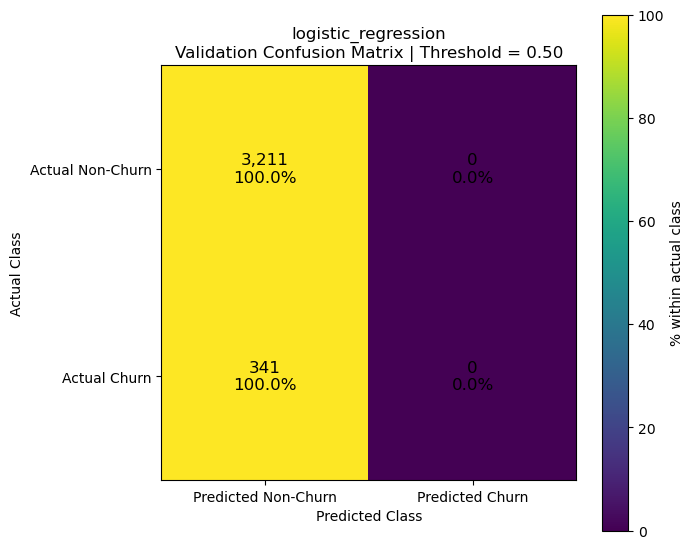

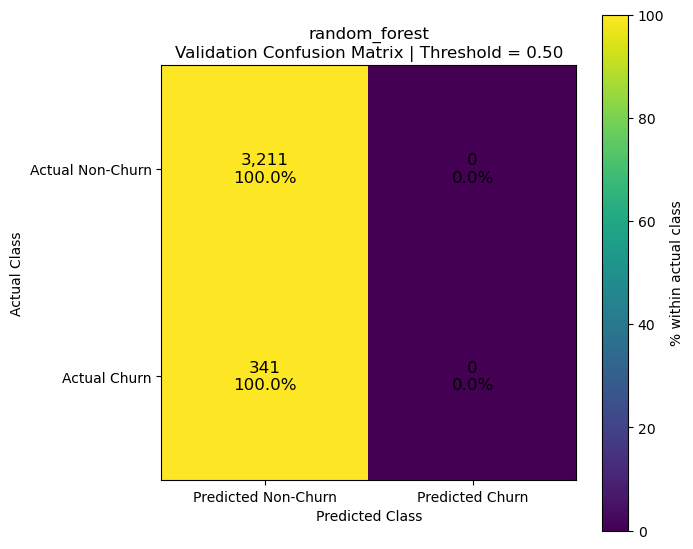

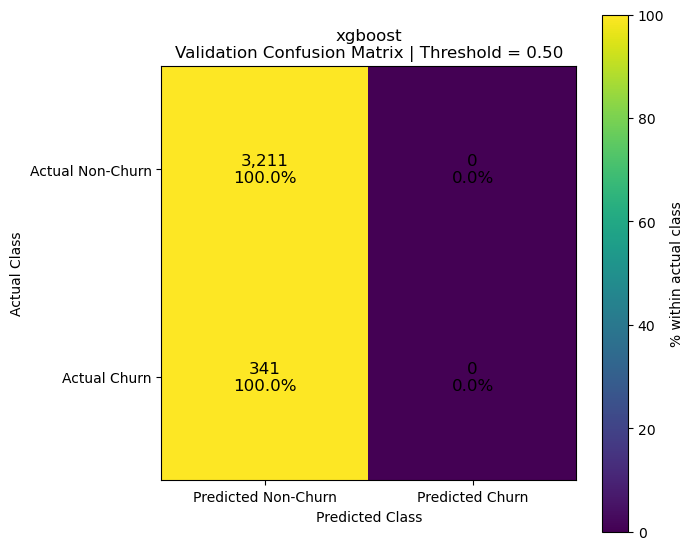

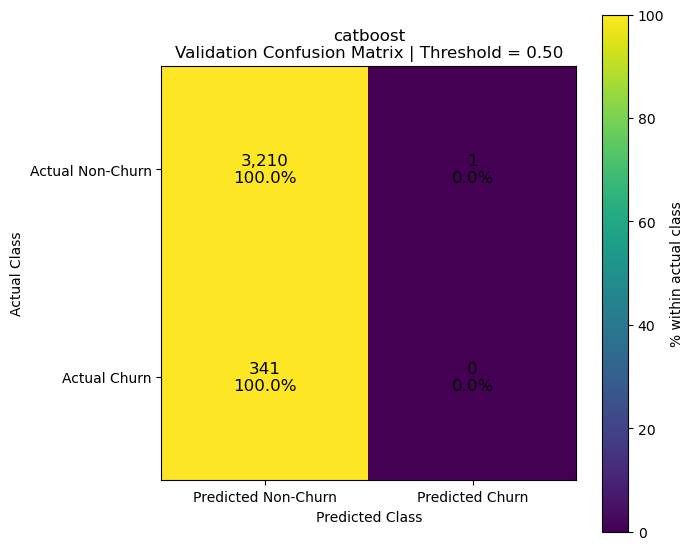

In [84]:
tuned_evaluator.show_all_confusion_matrices()

## 10. Study score distributions and operating rules


In [85]:
# INSPECT VALIDATION PROBABILITY DISTRIBUTIONS

import pandas as pd


probability_summary = []


for model_name, model in tuned_models.items():

    # Predicted probability of churn
    probabilities = model.predict_proba(
        X_validation_processed
    )[:, 1]


    probability_summary.append({

        "model": model_name,

        "min_probability":
            probabilities.min(),

        "25th_percentile":
            pd.Series(probabilities).quantile(0.25),

        "median":
            pd.Series(probabilities).median(),

        "75th_percentile":
            pd.Series(probabilities).quantile(0.75),

        "90th_percentile":
            pd.Series(probabilities).quantile(0.90),

        "95th_percentile":
            pd.Series(probabilities).quantile(0.95),

        "99th_percentile":
            pd.Series(probabilities).quantile(0.99),

        "max_probability":
            probabilities.max(),

        "customers_above_050":
            (probabilities >= 0.50).sum()
    })


probability_summary = pd.DataFrame(
    probability_summary
)


probability_summary

,model,min_probability,25th_percentile,median,75th_percentile,90th_percentile,95th_percentile,99th_percentile,max_probability,customers_above_050
0,logistic_regression,0.104208,0.104208,0.104208,0.104208,0.104208,0.104208,0.104208,0.104208,0
1,random_forest,0.020850,0.044140,0.056802,0.071249,0.087266,0.101629,0.149806,0.450063,0
2,xgboost,0.006485,0.029532,0.046017,0.070130,0.098885,0.122894,0.174213,0.337196,0
3,catboost,0.001042,0.016940,0.036953,0.062312,0.089747,0.110608,0.223698,0.535209,1


In [86]:
# XGBOOST THRESHOLD ANALYSIS

import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)


# GET XGBOOST VALIDATION PROBABILITIES

xgb_model = tuned_models["xgboost"]

xgb_probabilities = xgb_model.predict_proba(
    X_validation_processed
)[:, 1]


# THRESHOLDS TO TEST

thresholds = [
    0.03,
    0.04,
    0.05,
    0.06,
    0.07,
    0.08,
    0.09,
    0.10,
    0.12,
    0.15,
    0.20,
    0.25,
    0.30
]


threshold_results = []


# EVALUATE EACH THRESHOLD

for threshold in thresholds:

    predictions = (
        xgb_probabilities >= threshold
    ).astype(int)


    tn, fp, fn, tp = confusion_matrix(
        y_validation,
        predictions
    ).ravel()


    precision = precision_score(
        y_validation,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y_validation,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        y_validation,
        predictions,
        zero_division=0
    )


    customers_flagged = predictions.sum()

    flagged_percentage = (
        customers_flagged
        / len(predictions)
        * 100
    )


    threshold_results.append({

        "threshold": threshold,

        "customers_flagged":
            customers_flagged,

        "flagged_percentage":
            flagged_percentage,

        "precision":
            precision,

        "recall":
            recall,

        "f1":
            f1,

        "true_positives":
            tp,

        "false_positives":
            fp,

        "false_negatives":
            fn,

        "true_negatives":
            tn
    })


# RESULTS

threshold_results = pd.DataFrame(
    threshold_results
)

threshold_results

,threshold,customers_flagged,flagged_percentage,precision,recall,f1,true_positives,false_positives,false_negatives,true_negatives
0,0.03,2632,74.099099,0.106383,0.821114,0.188362,280,2352,61,859
1,0.04,2103,59.206081,0.116025,0.715543,0.199673,244,1859,97,1352
2,0.05,1558,43.862613,0.125802,0.574780,0.206424,196,1362,145,1849
3,0.06,1160,32.657658,0.131034,0.445748,0.202532,152,1008,189,2203
4,0.07,891,25.084459,0.116723,0.304985,0.168831,104,787,237,2424
5,0.08,656,18.468468,0.121951,0.234604,0.160481,80,576,261,2635
6,0.09,466,13.119369,0.137339,0.187683,0.158612,64,402,277,2809
7,0.10,344,9.684685,0.154070,0.155425,0.154745,53,291,288,2920
8,0.12,194,5.461712,0.149485,0.085044,0.108411,29,165,312,3046
9,0.15,74,2.083333,0.243243,0.052786,0.086747,18,56,323,3155


In [87]:
# XGBOOST TOP-K / LIFT ANALYSIS

import numpy as np
import pandas as pd


# GET VALIDATION PROBABILITIES

xgb_model = tuned_models["xgboost"]

xgb_probabilities = xgb_model.predict_proba(
    X_validation_processed
)[:, 1]


# CREATE ANALYSIS DATAFRAME

top_k_df = pd.DataFrame({

    "actual_churn":
        np.asarray(y_validation),

    "churn_probability":
        xgb_probabilities
})


# Rank highest-risk customers first
top_k_df = (

    top_k_df

    .sort_values(
        "churn_probability",
        ascending=False
    )

    .reset_index(drop=True)
)


# BASIC INFORMATION

total_customers = len(top_k_df)

total_churners = (
    top_k_df["actual_churn"].sum()
)

overall_prevalence = (
    total_churners / total_customers
)


print(
    f"Total customers: {total_customers:,}"
)

print(
    f"Total churners: {total_churners:,}"
)

print(
    f"Overall churn prevalence: "
    f"{overall_prevalence:.2%}"
)


# TOP-K LEVELS

k_values = [
    0.05,
    0.10,
    0.15,
    0.20,
    0.25,
    0.30,
    0.40,
    0.50
]


top_k_results = []


# CALCULATE TOP-K METRICS

for k in k_values:

    customers_targeted = int(
        np.ceil(total_customers * k)
    )

    targeted_group = (
        top_k_df.iloc[:customers_targeted]
    )

    churners_captured = (
        targeted_group["actual_churn"].sum()
    )


    # PRECISION@K
    # Of customers we targeted,
    # how many actually churned?

    precision_at_k = (
        churners_captured
        / customers_targeted
    )


    # RECALL@K
    # Of ALL actual churners,
    # how many did we capture?

    recall_at_k = (
        churners_captured
        / total_churners
    )


    # LIFT@K
    # How concentrated are churners compared
    # with selecting customers randomly?

    lift_at_k = (
        precision_at_k
        / overall_prevalence
    )


    top_k_results.append({

        "top_k_percentage":
            k * 100,

        "customers_targeted":
            customers_targeted,

        "churners_captured":
            int(churners_captured),

        "precision_at_k":
            precision_at_k,

        "recall_at_k":
            recall_at_k,

        "lift_at_k":
            lift_at_k
    })


# RESULTS

top_k_results = pd.DataFrame(
    top_k_results
)

top_k_results

Total customers: 3,552
Total churners: 341
Overall churn prevalence: 9.60%


,top_k_percentage,customers_targeted,churners_captured,precision_at_k,recall_at_k,lift_at_k
0,5.0,178,26,0.146067,0.076246,1.521500
1,10.0,356,54,0.151685,0.158358,1.580019
2,15.0,533,69,0.129456,0.202346,1.348467
3,20.0,711,89,0.125176,0.260997,1.303884
4,25.0,888,103,0.115991,0.302053,1.208211
5,30.0,1066,139,0.130394,0.407625,1.358239
6,40.0,1421,186,0.130894,0.545455,1.363444
7,50.0,1776,218,0.122748,0.639296,1.278592


## 11. Refit the selected model on train + validation


In [88]:
# COMBINE RAW TRAIN + VALIDATION

import pandas as pd


X_train_validation = pd.concat(
    [
        X_train,
        X_validation
    ],
    axis=0
).reset_index(drop=True)


y_train_validation = pd.concat(
    [
        y_train,
        y_validation
    ],
    axis=0
).reset_index(drop=True)


print(
    "Train + Validation X:",
    X_train_validation.shape
)

print(
    "Train + Validation y:",
    y_train_validation.shape
)

print(
    "\nTarget distribution:"
)

print(
    y_train_validation.value_counts()
)

print(
    "\nPrevalence:",
    y_train_validation.mean()
)

Train + Validation X: (10983, 31)
Train + Validation y: (10983,)

Target distribution:
churn_next_30d
0    10201
1      782
Name: count, dtype: int64

Prevalence: 0.07120094691796412


In [90]:
# COMBINE RAW TRAIN + VALIDATION

import pandas as pd


X_train_validation = pd.concat(
    [
        X_train,
        X_validation
    ],
    axis=0
).reset_index(drop=True)


y_train_validation = pd.concat(
    [
        y_train,
        y_validation
    ],
    axis=0
).reset_index(drop=True)


print(
    "Train + Validation X:",
    X_train_validation.shape
)

print(
    "Train + Validation y:",
    y_train_validation.shape
)

print(
    "\nPositive targets:",
    y_train_validation.sum()
)

print(
    "Prevalence:",
    f"{y_train_validation.mean():.2%}"
)

Train + Validation X: (10983, 31)
Train + Validation y: (10983,)

Positive targets: 782
Prevalence: 7.12%


In [91]:
# CREATE FINAL PREPROCESSOR

from modeling.preprocessor import ModelPreprocessor


final_preprocessor_builder = ModelPreprocessor(
    target_column=TARGET_COLUMN
)

In [93]:
# LOCK FINAL FEATURE SCHEMA

final_feature_columns = (
    X_train_validation.columns.tolist()
)


X_test_final = (
    X_test
    .reindex(
        columns=final_feature_columns
    )
)


print(
    "Final raw feature count:",
    len(final_feature_columns)
)

print(
    "Train + Validation:",
    X_train_validation.shape
)

print(
    "Test:",
    X_test_final.shape
)

Final raw feature count: 31
Train + Validation: (10983, 31)
Test: (6383, 31)


In [94]:
# BUILD FINAL PREPROCESSING PIPELINE

final_preprocessor = (
    final_preprocessor_builder
    .build_preprocessor(
        X_train_validation
    )
)

In [95]:
# FIT ON TRAIN + VALIDATION

X_train_validation_processed = (
    final_preprocessor.fit_transform(
        X_train_validation
    )
)


# TRANSFORM TEST ONLY

X_test_final_processed = (
    final_preprocessor.transform(
        X_test_final
    )
)


print(
    "Train + Validation processed:",
    X_train_validation_processed.shape
)

print(
    "Test processed:",
    X_test_final_processed.shape
)

Train + Validation processed: (10983, 48)
Test processed: (6383, 48)


In [96]:
# FINAL PREPROCESSING CHECKS

import numpy as np


print(
    "Missing values in Train + Validation:",
    np.isnan(
        X_train_validation_processed
    ).sum()
)

print(
    "Missing values in Test:",
    np.isnan(
        X_test_final_processed
    ).sum()
)


print(
    "\nInfinity in Train + Validation:",
    np.isinf(
        X_train_validation_processed
    ).sum()
)

print(
    "Infinity in Test:",
    np.isinf(
        X_test_final_processed
    ).sum()
)

Missing values in Train + Validation: 0
Missing values in Test: 0

Infinity in Train + Validation: 0
Infinity in Test: 0


In [97]:
import joblib
TUNED_XGBOOST_PATH = (
    PROJECT_ROOT
    / "models"
    / "v2_30d"
    / "rigorous_tuning"
    / "best_xgboost.joblib"
)


tuned_xgboost = joblib.load(
    TUNED_XGBOOST_PATH
)


print("Loaded tuned XGBoost:")
print(tuned_xgboost)

Loaded tuned XGBoost:
XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.7, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.03, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=3, max_leaves=None,
              min_child_weight=5, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=-1,
              num_parallel_tree=None, ...)


In [98]:
# CLONE TUNED XGBOOST CONFIGURATION

from sklearn.base import clone


final_xgboost = clone(
    tuned_xgboost
)

In [99]:
# RETRAIN ON TRAIN + VALIDATION

final_xgboost.fit(
    X_train_validation_processed,
    y_train_validation
)


print(
    "Tuned XGBoost configuration "
    "retrained on Train + Validation successfully."
)

Tuned XGBoost configuration retrained on Train + Validation successfully.


## 12. Evaluate



In [102]:
import importlib
import modeling.model_tester

importlib.reload(
    modeling.model_tester
)

from modeling.model_tester import ModelTester

In [103]:
FINAL_TEST_DIR = (
    PROJECT_ROOT
    / "models"
    / "v2_30d"
    / "final_test"
)


tester = ModelTester(

    threshold=0.50,

    top_k=100,

    results_dir=FINAL_TEST_DIR
)

In [105]:
test_metadata = (
    final_preprocessor_builder.create_metadata(
        test_df
    )
)

print(test_metadata.shape)
display(test_metadata.head())

(6383, 3)


,account_id,snapshot_date,churn_next_30d
0,A-00bed1,2024-08-25,0
1,A-00cac8,2024-08-25,0
2,A-0158bb,2024-08-25,0
3,A-016043,2024-08-25,0
4,A-019782,2024-08-25,0


In [106]:
assert (
    len(X_test_final_processed)
    == len(y_test)
    == len(test_metadata)
)

print("✓ Test data aligned.")

✓ Test data aligned.


In [107]:
final_test_results = tester.test(

    models={
        "xgboost": final_xgboost
    },

    X_test=X_test_final_processed,

    y_test=y_test,

    test_metadata=test_metadata
)

final_test_results

Testing xgboost...

FINAL TEST RESULTS SAVED

Models tested: 1
Prediction files saved: 1
Confusion matrices saved: 1

Results directory:
C:\Users\kipch\PycharmProjects\Customer_retention\models\v2_30d\final_test

Overall test metrics:
C:\Users\kipch\PycharmProjects\Customer_retention\models\v2_30d\final_test\test_metrics.csv

Weekly Top-100 metrics:
C:\Users\kipch\PycharmProjects\Customer_retention\models\v2_30d\final_test\weekly_top_100_metrics.csv


,model,threshold,rows,positive_rows,prevalence,pr_auc,pr_auc_lift,roc_auc,brier_score,accuracy,...,false_positives,false_negatives,true_negatives,weeks_evaluated,total_actual_churners,total_captured_churners,aggregate_recall_at_100,mean_precision_at_100,mean_recall_at_100,mean_lift_at_100
0,xgboost,0.5,6383,769,0.120476,0.147391,1.223399,0.572874,0.107543,0.879524,...,0,769,5614,15,769,235,0.305592,0.156667,0.309443,1.308182


## 13. evaluating based on retention capacity


In [108]:
weekly_test = tester.weekly_results.copy()

display(
    weekly_test[
        [
            "snapshot_date",
            "eligible_customers",
            "k_used",
            "actual_churners",
            "captured_churners",
            "precision_at_100",
            "recall_at_100",
            "lift_at_100"
        ]
    ]
)

,snapshot_date,eligible_customers,k_used,actual_churners,captured_churners,precision_at_100,recall_at_100,lift_at_100
0,2024-08-25,379,100,40,14,0.14,0.350000,1.326500
1,2024-09-01,385,100,39,13,0.13,0.333333,1.283333
2,2024-09-08,393,100,45,18,0.18,0.400000,1.572000
3,2024-09-15,395,100,44,16,0.16,0.363636,1.436364
4,2024-09-22,406,100,48,16,0.16,0.333333,1.353333
5,2024-09-29,414,100,52,16,0.16,0.307692,1.273846
6,2024-10-06,418,100,47,15,0.15,0.319149,1.334043
7,2024-10-13,422,100,43,11,0.11,0.255814,1.079535
8,2024-10-20,430,100,41,11,0.11,0.268293,1.153659
9,2024-10-27,436,100,48,13,0.13,0.270833,1.180833


In [109]:
weekly_test["percent_targeted"] = (
    weekly_test["k_used"]
    /
    weekly_test["eligible_customers"]
    * 100
)

display(
    weekly_test[
        [
            "snapshot_date",
            "eligible_customers",
            "k_used",
            "percent_targeted",
            "actual_churners",
            "captured_churners",
            "lift_at_100"
        ]
    ]
)

,snapshot_date,eligible_customers,k_used,percent_targeted,actual_churners,captured_churners,lift_at_100
0,2024-08-25,379,100,26.385224,40,14,1.326500
1,2024-09-01,385,100,25.974026,39,13,1.283333
2,2024-09-08,393,100,25.445293,45,18,1.572000
3,2024-09-15,395,100,25.316456,44,16,1.436364
4,2024-09-22,406,100,24.630542,48,16,1.353333
5,2024-09-29,414,100,24.154589,52,16,1.273846
6,2024-10-06,418,100,23.923445,47,15,1.334043
7,2024-10-13,422,100,23.696682,43,11,1.079535
8,2024-10-20,430,100,23.255814,41,11,1.153659
9,2024-10-27,436,100,22.935780,48,13,1.180833


In [127]:
test_predictions = (
    tester.prediction_results[
        "xgboost"
    ]
    .copy()
)

display(
    test_predictions.head()
)

,account_id,snapshot_date,churn_next_30d,actual,probability,prediction
0,A-00bed1,2024-08-25,0,0,0.048810,0
1,A-00cac8,2024-08-25,0,0,0.044689,0
2,A-0158bb,2024-08-25,0,0,0.059841,0
3,A-016043,2024-08-25,0,0,0.112600,0
4,A-019782,2024-08-25,0,0,0.084182,0


In [111]:
top_k_results = []


for k in [25, 50, 75, 100]:

    summary, weekly_results = (
        tester.calculate_weekly_top_k_metrics(
            y_true=test_predictions["actual"],
            probabilities=test_predictions["probability"],
            metadata=test_predictions,
        )
    )

    # The current method uses self.top_k,
    # so temporarily update it

### Experimental implementation notes


In [114]:
def calculate_weekly_top_k_metrics(
    self,
    y_true,
    probabilities,
    metadata,
    k=None
):

    if k is None:
        k = self.top_k

In [134]:
tester = ModelTester(
    threshold=0.50,
    top_k=100,
    results_dir=FINAL_TEST_DIR
)

In [135]:
capacity_results = []


for k in [25, 50, 75, 100]:

    summary, _ = (
        tester.calculate_weekly_top_k_metrics(

            y_true=
                test_predictions["actual"],

            probabilities=
                test_predictions["probability"],

            metadata=
                test_predictions,

            k=k
        )
    )


    summary["top_k"] = k

    capacity_results.append(
        summary
    )


capacity_results = (
    pd.DataFrame(
        capacity_results
    )
)


display(
    capacity_results
)

,top_k,weeks_evaluated,total_actual_churners,total_captured_churners,aggregate_recall_at_25,mean_precision_at_25,mean_recall_at_25,mean_lift_at_25,mean_percent_targeted,aggregate_recall_at_50,...,mean_recall_at_50,mean_lift_at_50,aggregate_recall_at_75,mean_precision_at_75,mean_recall_at_75,mean_lift_at_75,aggregate_recall_at_100,mean_precision_at_100,mean_recall_at_100,mean_lift_at_100
0,25,15,769,59,0.076723,0.157333,0.080365,1.347498,5.904126,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,50,15,769,104,NaN,NaN,NaN,NaN,11.808252,0.135241,...,0.140884,1.178767,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,75,15,769,157,NaN,NaN,NaN,NaN,17.712379,NaN,...,NaN,NaN,0.204161,0.139556,0.210397,1.176994,NaN,NaN,NaN,NaN
3,100,15,769,235,NaN,NaN,NaN,NaN,23.616505,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.305592,0.156667,0.309443,1.308182


In [131]:
# FORCE RELOAD MODEL TESTER

import sys
import importlib
import inspect

import modeling.model_tester


# Remove cached module
if "modeling.model_tester" in sys.modules:
    del sys.modules["modeling.model_tester"]


# Import fresh module
import modeling.model_tester


# Import fresh class
from modeling.model_tester import ModelTester


print(
    "Loaded from:",
    modeling.model_tester.__file__
)

print(
    "\nClass method signature:",
    inspect.signature(
        ModelTester.calculate_weekly_top_k_metrics
    )
)

Loaded from: C:\Users\kipch\PycharmProjects\Customer_retention\my_src\modeling\model_tester.py

Class method signature: (self, y_true, probabilities, metadata, k=None)


In [133]:
import inspect

print(
    inspect.signature(
        tester.calculate_weekly_top_k_metrics
    )
)

(y_true, probabilities, metadata)


In [136]:
capacity_results = []


for k in [25, 50, 75, 100]:

    summary, weekly_results = (
        tester.calculate_weekly_top_k_metrics(
            y_true=test_predictions["actual"],
            probabilities=test_predictions["probability"],
            metadata=test_predictions,
            k=k
        )
    )


    capacity_results.append(
        {
            "top_k":
                k,

            "weeks_evaluated":
                summary["weeks_evaluated"],

            "total_churners":
                summary["total_actual_churners"],

            "churners_captured":
                summary["total_captured_churners"],

            "aggregate_recall":
                summary[
                    f"aggregate_recall_at_{k}"
                ],

            "mean_precision":
                summary[
                    f"mean_precision_at_{k}"
                ],

            "mean_recall":
                summary[
                    f"mean_recall_at_{k}"
                ],

            "mean_lift":
                summary[
                    f"mean_lift_at_{k}"
                ],

            "mean_percent_targeted":
                summary["mean_percent_targeted"]
        }
    )


capacity_results = pd.DataFrame(
    capacity_results
)


display(
    capacity_results.round(4)
)

,top_k,weeks_evaluated,total_churners,churners_captured,aggregate_recall,mean_precision,mean_recall,mean_lift,mean_percent_targeted
0,25,15,769,59,0.0767,0.1573,0.0804,1.3475,5.9041
1,50,15,769,104,0.1352,0.1387,0.1409,1.1788,11.8083
2,75,15,769,157,0.2042,0.1396,0.2104,1.1770,17.7124
3,100,15,769,235,0.3056,0.1567,0.3094,1.3082,23.6165


## 14. Save production artifacts


In [137]:
from pathlib import Path
import joblib


# PRODUCTION ARTIFACT DIRECTORY

PRODUCTION_DIR = (
    PROJECT_ROOT
    / "models"
    / "v2_30d"
    / "production"
)

PRODUCTION_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# SAVE FINAL MODEL

joblib.dump(
    final_xgboost,
    PRODUCTION_DIR / "xgboost_model.joblib"
)


# SAVE FITTED PREPROCESSOR

joblib.dump(
    final_preprocessor,
    PRODUCTION_DIR / "preprocessor.joblib"
)


# SAVE RAW FEATURE SCHEMA

joblib.dump(
    final_feature_columns,
    PRODUCTION_DIR / "feature_columns.joblib"
)


print(
    "Production artifacts saved to:"
)

print(
    PRODUCTION_DIR
)

Production artifacts saved to:
C:\Users\kipch\PycharmProjects\Customer_retention\models\v2_30d\production


## 15. Test the production predictor


In [157]:
import sys
import importlib

# Remove old cached module
sys.modules.pop(
    "feature_engineering.feature_engineer",
    None
)

# Clear import cache
importlib.invalidate_caches()

# Import fresh version
from feature_engineering.feature_engineer import FeatureEngineer

# Recreate object
feature_engineer = FeatureEngineer(
    engine=engine
)

In [158]:
from prediction.churn_predictor import ChurnPredictor

predictor = ChurnPredictor.from_files(
    engine=engine,
    model_path=PRODUCTION_DIR / "xgboost_model.joblib",
    preprocessor_path=PRODUCTION_DIR / "preprocessor.joblib",
    feature_columns_path=PRODUCTION_DIR / "feature_columns.joblib",
    snapshot_builder=snapshot_builder,
    feature_engineer=feature_engineer
)

In [159]:
predictions = predictor.predict(
    prediction_date="2024-12-01",
    threshold=0.10
)

display(predictions.head(25))

,account_id,prediction_date,risk_rank,churn_probability,churn_prediction,threshold_used
0,A-5a215a,2024-12-01,1,0.243256,1,0.1
1,A-9289f6,2024-12-01,2,0.214217,1,0.1
2,A-d82ef9,2024-12-01,3,0.209898,1,0.1
3,A-3c1a3f,2024-12-01,4,0.198709,1,0.1
4,A-956988,2024-12-01,5,0.180295,1,0.1
5,A-eb7fac,2024-12-01,6,0.175467,1,0.1
6,A-054577,2024-12-01,7,0.172918,1,0.1
7,A-b179bf,2024-12-01,8,0.169907,1,0.1
8,A-52dd88,2024-12-01,9,0.166419,1,0.1
9,A-1f559b,2024-12-01,10,0.166159,1,0.1
